In [53]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [54]:
X, y_true = make_blobs(n_samples=500, centers=3, cluster_std=4, random_state=42)

In [55]:
df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])

In [56]:
df

,Feature_1,Feature_2
0,-2.282534,-9.692815
1,-6.147668,1.755990
2,13.399091,-1.260023
3,-4.077630,3.160226
4,9.444735,0.340868
...,...,...
495,-1.282205,-3.181575
496,-2.817604,10.378894
497,3.296740,8.649256
498,-8.970519,-2.684073


In [57]:
scaler = StandardScaler()
X_sclaed = scaler.fit_transform(df)

In [58]:
inertia = []
K_range = range(1, 11)

In [59]:
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_sclaed)
    inertia.append(kmeans.inertia_)

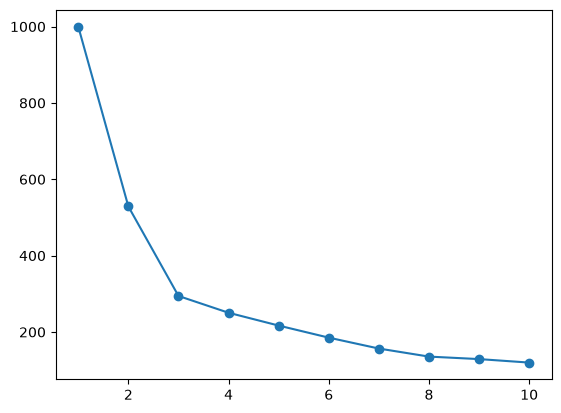

In [60]:
plt.plot(K_range, inertia, marker='o')

In [61]:
kmeans_final = KMeans(n_clusters=3, random_state=42)

In [62]:
cluster_labels = kmeans_final.fit_predict(X_sclaed)

In [63]:
df['cluster'] = cluster_labels

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

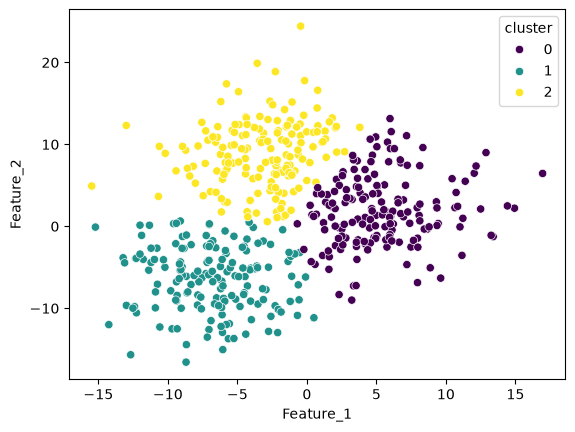

In [64]:
sns.scatterplot(x=df['Feature_1'],
                y=df['Feature_2'],
                hue=df['cluster'],
                palette='viridis')

In [65]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

In [66]:
X, y_true = make_moons(n_samples=500, noise=0.05, random_state=42)

In [67]:
df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])

In [68]:
scaler = StandardScaler()
X_sclaed = scaler.fit_transform(df)

In [69]:
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_label = kmeans.fit_predict(X_sclaed)

In [70]:
df['kmeans_cluster'] = kmeans_label

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

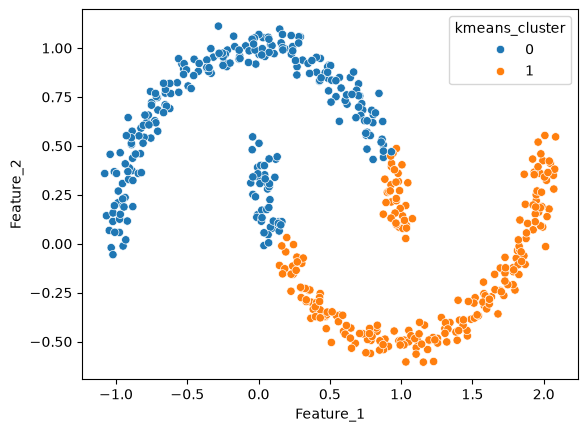

In [71]:
sns.scatterplot(x=df['Feature_1'],
                y=df['Feature_2'],
                hue=df['kmeans_cluster'],
                palette='tab10')

In [73]:
db_scan = DBSCAN(eps=0.3, min_samples=5)
dbscan_label = db_scan.fit_predict(X_sclaed)

In [74]:
df['dbscan_cluster'] = dbscan_label

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

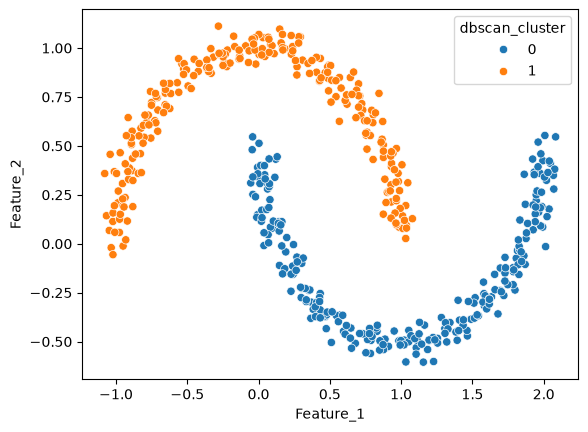

In [75]:
sns.scatterplot(x=df['Feature_1'],
                y=df['Feature_2'],
                hue=df['dbscan_cluster'],
                palette='tab10')